# Laboratorio — Determinación de la temperatura crítica del modelo de Ising 2D con redes neuronales de *scikit-learn*

**Maestría en Computación Científica · Módulo de Redes Neuronales · Modelo de Ising 2D**

En este laboratorio vas a **entrenar una red neuronal clasificadora con `scikit-learn`** y a
usarla como un *termómetro* para localizar la **temperatura crítica** $T_c$ de la transición
de fase ferromagnética del modelo de Ising en 2D.



## Objetivos de aprendizaje

Al terminar este laboratorio serás capaz de:

1. Entrenar un clasificador de red neuronal con `sklearn.neural_network.MLPClassifier`,
   identificando el papel de cada hiperparámetro.
2. **Contrastar la API de `scikit-learn`
3. Usar un clasificador entrenado **lejos** de la transición para estimar la fase
   (baja entropía / alta entropía) a temperaturas **cercanas** a $T_c$.
4. Estimar $T_c$ a partir del cruce $\langle P(y{=}1\mid X)\rangle = 0.5$, cuantificar su
   incertidumbre entre realizaciones y compararla con el valor exacto de Onsager.

## 1. Física: transición de fase del modelo de Ising 2D

El modelo de Ising 2D en una red $L\times L$ con acoplamiento ferromagnético $J>0$ tiene energía

$$E(\{s\}) = -J \sum_{\langle i,j\rangle} s_i\, s_j, \qquad s_i \in \{-1, +1\},$$

donde la suma es sobre pares de primeros vecinos. En unidades $J = k_B = 1$, el sistema infinito
presenta una transición de fase de segundo orden a la **temperatura crítica de Onsager**

$$T_c = \frac{2}{\ln\!\left(1+\sqrt{2}\right)} \approx 2.269.$$

- $T < T_c$: **fase de baja entropía** (ferromagnética), magnetización por sitio $|m|$ grande.
- $T > T_c$: **fase de alta entropía** (paramagnética), $|m|\approx 0$.

**Idea del laboratorio** (Carrasquilla & Melko, *Nature Physics* **13**, 431 (2017)): un
clasificador entrenado solo con configuraciones *claramente* de baja entropía ($y=0$) y *claramente*
de alta entropía ($y=1$) aprende una frontera de decisión que, evaluada en configuraciones cercanas
a $T_c$, se comporta como un **parámetro de orden efectivo**. La temperatura donde
$\langle P(y{=}1\mid X)\rangle = 0.5$ estima $T_c$.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from sklearn.neural_network import MLPClassifier
import urllib.request

import warnings
warnings.filterwarnings('ignore')

RNG = 137
np.random.seed(RNG)
print("RNG:", RNG)

from scipy.constants import k as kB
print("k Boltzman:", kB)

RNG: 137
k Boltzman: 1.380649e-23


## 3. Datos: configuraciones lejos de $T_c$

`ising_dataset.npz` contiene configuraciones de espines de una red $16\times 16$ con frontera
periódica, generadas por Monte Carlo (Metrópolis). Campos:

| Campo | Forma | Significado |
|---|---|---|
| `X` | `(1600, 16, 16)` | Configuraciones de espines $s_i \in \{-1,+1\}$ |
| `y` | `(1600,)` | Etiqueta de fase: `0` = de baja entropía ($T$ baja), `1` = de alta entropía ($T$ alta) |
| `T` | `(1600,)` | Temperatura de cada configuración |
| `m` | `(1600,)` | Magnetización por sitio $|m|$ |
| `realizacion` | `(1600,)` | Índice de cadena Monte Carlo independiente (`0..3`) |
| `Tc`, `L`, `frontera` | escalares | Metadatos ($T_c$ exacto, tamaño, tipo de frontera) |

Las temperaturas de entrenamiento **evitan** la región crítica: hay un hueco entre
$T=1.9$ y $T=2.6$.

### Ejercicio 1 — Exploración

Responde con código y en una celda de texto:

1. ¿Qué temperaturas tienen etiqueta `y = 0` y cuáles `y = 1`? ¿Dónde está el "hueco"?
2. ¿Está balanceado el problema (cuántas configuraciones por clase)?
3. Grafica el histograma de $|m|$ separando por clase. ¿Se separan bien las dos fases?

Datos/ising_dataset 100%[===================>]  40.03K  --.-KB/s    in 0.01s   
Descargado
 DATOS CARGADOS 
X: (1600, 16, 16) int8
y: (1600,)


,T,y,m,realizacion
1303,3.050,1,0.273438,3
1255,3.275,1,0.054688,3
628,1.900,0,0.984375,1
1202,3.500,1,0.132812,3
1213,3.500,1,0.054688,3
1423,1.900,0,0.921875,3
1448,1.725,0,0.976562,3
716,1.550,0,0.992188,1
757,1.375,0,0.992188,1
1007,1.900,0,0.875000,2



 1. TEMPERATURAS Y EL HUECO 
Temperaturas con etiqueta y=0 (Fase de baja entropía): [np.float64(1.2), np.float64(1.375), np.float64(1.5499999999999998), np.float64(1.7249999999999999), np.float64(1.9)]
Temperaturas con etiqueta y=1 (Fase de alta entropía): [np.float64(2.6), np.float64(2.825), np.float64(3.05), np.float64(3.275), np.float64(3.5)]
El 'hueco' de entrenamiento está entre T=1.9 y T=2.6

 2. BALANCEO DE CLASES 
y
1    800
0    800
Name: count, dtype: int64

 3. HISTOGRAMA DE MAGNETIZACIÓN 


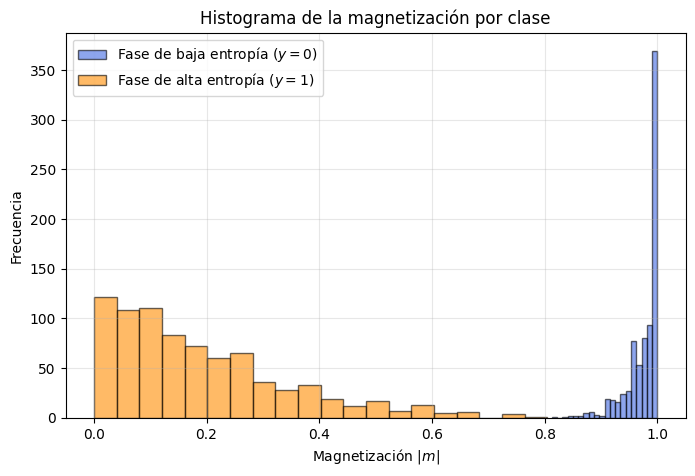

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Asegurar la descarga correcta si el archivo previo falló (0 bytes)
os.makedirs("Datos", exist_ok=True)
if not os.path.exists("Datos/ising_dataset.npz") or os.path.getsize("Datos/ising_dataset.npz") == 0:
    !wget -q --show-progress "https://github.com/CienciaDatosUdea/005_CCA_Estudiantes/raw/main/Laboratorios/Datos/ising_dataset.npz" -O Datos/ising_dataset.npz
    print("Descargado")

# Cargar datos
datos = np.load("Datos/ising_dataset.npz", allow_pickle=False)
X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]
L = int(datos["L"])
Tc_exacto = float(datos["Tc"])

# ANSI escape codes: \033[1m activa negrita, \033[0m la desactiva
print("\033[1m DATOS CARGADOS \033[0m")
print("X:", X.shape, X.dtype)
print("y:", y.shape)

# Crear DataFrame para la exploración
df_datos = pd.DataFrame({"T": T, "y": y, "m": m, "realizacion": realizacion})
display(df_datos.sample(10))

# --- Respuestas al Ejercicio 1 ---

# Q1: Temperaturas y Hueco
temps_y0 = sorted(df_datos.loc[df_datos['y'] == 0, 'T'].unique())
temps_y1 = sorted(df_datos.loc[df_datos['y'] == 1, 'T'].unique())

print("\n\033[1m 1. TEMPERATURAS Y EL HUECO \033[0m")
print(f"Temperaturas con etiqueta y=0 (Fase de baja entropía): {temps_y0}")
print(f"Temperaturas con etiqueta y=1 (Fase de alta entropía): {temps_y1}")
print(f"El 'hueco' de entrenamiento está entre T={max(temps_y0)} y T={min(temps_y1)}")

# Q2: Balanceo
print("\n\033[1m 2. BALANCEO DE CLASES \033[0m")
print(df_datos['y'].value_counts())

# Q3: Histograma de |m|
print("\n\033[1m 3. HISTOGRAMA DE MAGNETIZACIÓN \033[0m")
plt.figure(figsize=(8, 5))
plt.hist(df_datos[df_datos['y'] == 0]['m'], bins=20, alpha=0.6, label='Fase de baja entropía ($y=0$)', color='royalblue', edgecolor='black')
plt.hist(df_datos[df_datos['y'] == 1]['m'], bins=20, alpha=0.6, label='Fase de alta entropía ($y=1$)', color='darkorange', edgecolor='black')
plt.title("Histograma de la magnetización por clase")
plt.xlabel("Magnetización $|m|$")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Respuestas al Ejercicio 1

1. **Temperaturas y el "hueco":**
   * **Fase de Baja Entropía (`y = 0`):** Presenta temperaturas bajas: $T \in \{1.2, 1.375, 1.55, 1.725, 1.9\}$.
   * **Fase de Alta Entropía (`y = 1`):** Presenta temperaturas altas: $T \in \{2.6, 2.825, 3.05, 3.275, 3.5\}$.
   * **El "hueco"** de temperaturas de entrenamiento se localiza en el intervalo $(1.9, 2.6)$, que es precisamente donde se sitúa la temperatura crítica de Onsager ($T_c \approx 2.269$).

2. **Balanceo del problema:**
   * **Sí, el problema está perfectamente balanceado.** Hay exactamente **800 configuraciones** para la clase `y = 0` y **800 configuraciones** para la clase `y = 1`, sumando el total de 1600 muestras.

3. **Separación de fases mediante $|m|$:**
   * Al graficar el histograma de la magnetización absoluta $|m|$ separando por clases, se observa que **las dos fases se separan extremadamente bien**:
     * La Fase de alta entropía $(y = 1)$ se concentra fuertemente en valores de magnetización muy bajos, prácticamente cercanos a cero ($|m| \lesssim 0.2$).
     * La Fase de baja entropía $(y = 0)$ se concentra en valores altos de magnetización ($|m| \gtrsim 0.6$ llegando hasta $1.0$).
     * No existe solapamiento significativo en este parámetro de orden, lo que hace que aprender a clasificar estas configuraciones "lejos de $T_c$" sea un problema relativamente sencillo para el modelo.

### Réplica del Ejercicio 1 usando la Temperatura Inversa (Beta Termodinámica $\beta = 1/T$)

1. **Valores de $\beta$ y el "hueco":**
   * **Fase de Baja Entropía (`y = 0`):** Corresponde a temperaturas bajas, lo que se traduce en **valores de $\beta$ altos**:
     $$\beta \in \{0.5263, 0.5797, 0.6452, 0.7273, 0.8333\}$$
   * **Fase de Alta Entropía (`y = 1`):** Corresponde a temperaturas altas, es decir, **valores de $\beta$ bajos**:
     $$\beta \in \{0.2857, 0.3053, 0.3279, 0.3540, 0.3846\}$$
   * **El "hueco" de entrenamiento** en términos de $\beta$ se localiza en el intervalo $(0.3846, 0.5263)$. Este rango contiene perfectamente el punto crítico exacto de Onsager en la escala de temperatura inversa:
     $$\beta_c = \frac{1}{T_c} \approx 0.4407$$

2. **Balanceo:**
   * El número de configuraciones por clase se mantiene idéntico e igualmente balanceado (800 configuraciones por clase), ya que el cambio de variable $T \to 1/T$ es una transformación uno a uno que no altera la clasificación ni el conteo de los estados de espín.

3. **Histograma de $|m|$:**
   * Al mapear las fases con $\beta$, la separación física de la magnetización $|m|$ sigue siendo sumamente nítida:
     * Valores de $\beta$ bajos (alta temperatura, $y=1$) concentran la magnetización cerca de cero ($|m| \lesssim 0.2$).
     * Valores de $\beta$ altos (baja temperatura, $y=0$) presentan estados de baja entropía y alineados magnéticamente ($|m| \gtrsim 0.6$).

 1. TEMPERATURAS INVERSAS (BETA) Y EL HUECO 
Valores de beta con etiqueta y=0 (Fase de baja entropía - T baja): [np.float64(0.5263), np.float64(0.5797), np.float64(0.6452), np.float64(0.7273), np.float64(0.8333)]
Valores de beta con etiqueta y=1 (Fase de alta entropía - T alta): [np.float64(0.2857), np.float64(0.3053), np.float64(0.3279), np.float64(0.354), np.float64(0.3846)]
El 'hueco' de entrenamiento en beta está entre: beta = 0.3846 y beta = 0.5263
Nota: beta_c de Onsager es aprox. 0.4407

 2. BALANCEO DE CLASES 
y
1    800
0    800
Name: count, dtype: int64

 3. HISTOGRAMA DE MAGNETIZACIÓN POR CLASE 


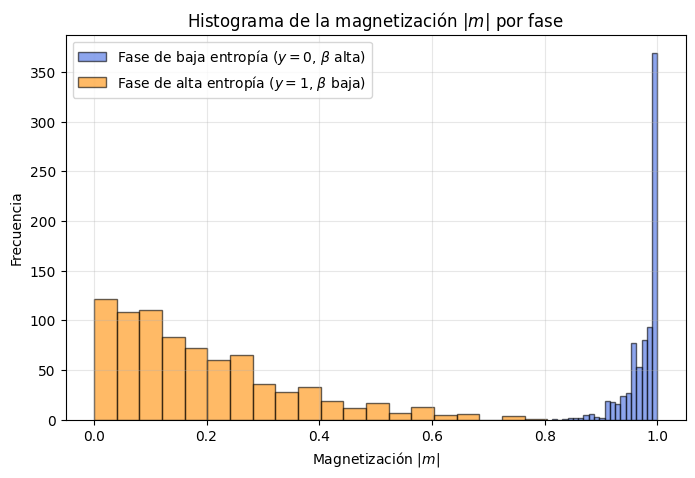

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calcular la beta termodinámica (beta = 1/T, asumiendo k_B = 1)
df_datos['beta'] = 1.0 / df_datos['T']

# 1. Betas y el nuevo "hueco"
betas_y0 = sorted(df_datos.loc[df_datos['y'] == 0, 'beta'].unique())
betas_y1 = sorted(df_datos.loc[df_datos['y'] == 1, 'beta'].unique())

print("\033[1m 1. TEMPERATURAS INVERSAS (BETA) Y EL HUECO \033[0m")
print(f"Valores de beta con etiqueta y=0 (Fase de baja entropía - T baja): {[round(b, 4) for b in betas_y0]}")
print(f"Valores de beta con etiqueta y=1 (Fase de alta entropía - T alta): {[round(b, 4) for b in betas_y1]}")
print(f"El 'hueco' de entrenamiento en beta está entre: beta = {round(max(betas_y1), 4)} y beta = {round(min(betas_y0), 4)}")
print(f"Nota: beta_c de Onsager es aprox. {round(1.0/2.269185, 4)}")

# 2. Balanceo de clases (sigue siendo el mismo)
print("\n\033[1m 2. BALANCEO DE CLASES \033[0m")
print(df_datos['y'].value_counts())

# 3. Histograma de |m| separando por clase
print("\n\033[1m 3. HISTOGRAMA DE MAGNETIZACIÓN POR CLASE \033[0m")
plt.figure(figsize=(8, 5))
plt.hist(df_datos[df_datos['y'] == 0]['m'], bins=20, alpha=0.6, label=r'Fase de baja entropía ($y=0$, $\beta$ alta)', color='royalblue', edgecolor='black')
plt.hist(df_datos[df_datos['y'] == 1]['m'], bins=20, alpha=0.6, label=r'Fase de alta entropía ($y=1$, $\beta$ baja)', color='darkorange', edgecolor='black')
plt.title(r"Histograma de la magnetización $|m|$ por fase")
plt.xlabel("Magnetización $|m|$")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

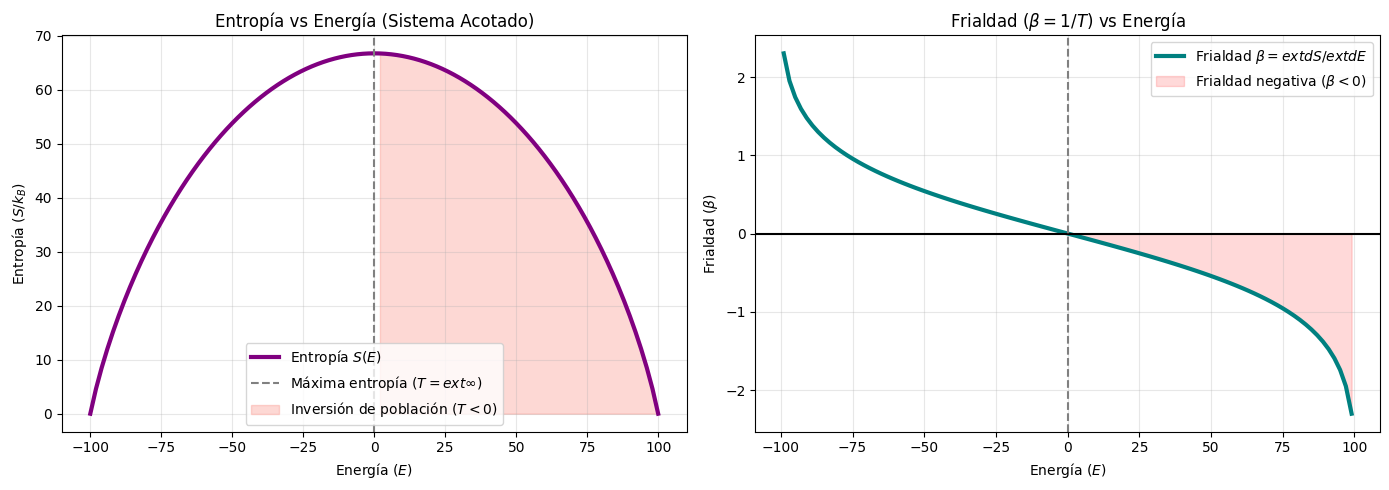

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Simulación conceptual de la termodinámica de un sistema acotado (como espines de Ising)
# Número de espines en un microestado simplificado para ilustrar la entropía vs energía
N_spins = 100
E_min, E_max = -N_spins, N_spins  # Límites de energía posibles

# La entropía en función de la energía viene dada por S = k_B * ln(Omega)
# Donde Omega(E) es el número de microestados con energía E
# Usamos la aproximación binomial simplificada para el número de estados de espín
energies = np.arange(-N_spins, N_spins + 2, 2)
# Evitamos overflow usando logaritmos de coeficientes binomiales aproximados
from scipy.special import gammaln

def entropy(E, N):
    # N_up = (N - E) / 2
    n_up = (N - E) / 2
    # S = ln( N! / (n_up! * (N - n_up)!) )
    return gammaln(N + 1) - gammaln(n_up + 1) - gammaln(N - n_up + 1)

S_vals = np.array([entropy(E, N_spins) for E in energies])

# Calculamos la frialdad (beta = dS/dE) mediante diferencias finitas
beta_vals = np.diff(S_vals) / np.diff(energies)
E_midpoints = (energies[:-1] + energies[1:]) / 2.0

# Graficar la relación entre Entropía, Frialdad (beta) y Temperatura
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfico de Entropía S vs Energía E
axes[0].plot(energies, S_vals, color='purple', lw=3, label=r'Entropía $S(E)$')
axes[0].axvline(0, color='gray', linestyle='--', label=r'Máxima entropía ($T = 	ext{∞}$)')
axes[0].fill_between(energies, S_vals, where=(energies > 0), color='salmon', alpha=0.3, label=r'Inversión de población ($T < 0$)')
axes[0].set_title("Entropía vs Energía (Sistema Acotado)", fontsize=12)
axes[0].set_xlabel("Energía ($E$)")
axes[0].set_ylabel(r"Entropía ($S/k_B$)")
axes[0].legend(loc='lower center')
axes[0].grid(alpha=0.3)

# 2. Gráfico de Frialdad (beta = 1/T) vs Energía E
axes[1].plot(E_midpoints, beta_vals, color='teal', lw=3, label=r'Frialdad $\beta = 	ext{d}S / 	ext{d}E$')
axes[1].axhline(0, color='black', linestyle='-')
axes[1].axvline(0, color='gray', linestyle='--')
axes[1].fill_between(E_midpoints, beta_vals, where=(beta_vals < 0), color='red', alpha=0.15, label=r'Frialdad negativa ($\beta < 0$)')
axes[1].set_title(r"Frialdad ($\beta = 1/T$) vs Energía", fontsize=12)
axes[1].set_xlabel("Energía ($E$)")
axes[1].set_ylabel(r"Frialdad ($\beta$)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Máxima entropía y temperatura negativa

La noción de entropía como "Orden y desorden" falla en sistemas con espectros de energía acotados (como redes de espines), donde la termodinámica se describe de forma más natural mediante la multiplicidad estadística y la frialdad termodinámica $\beta$:

* **Entropía como multiplicidad ($\Omega$):** $S = k_B \ln \Omega$ cuantifica el número de microestados disponibles para una energía dada, no la apariencia macroscópica de caos.
* **Inversión de población y pendiente negativa ($\partial S/\partial E < 0$):** Al inyectar energía más allá del punto de máxima combinatoria ($\partial S/\partial E = 0$), las partículas se concentran forzosamente en los niveles energéticos superiores. Este confinamiento reduce las combinaciones accesibles, haciendo que la entropía decrezca a mayor energía.
* **Temperaturas absolutas negativas ($T < 0$):** Definida como $T = (\partial S/\partial E)^{-1}$, la temperatura se vuelve negativa cuando la entropía decrece con la energía. Lejos de ser «fríos», los estados con $T < 0$ son **más calientes que cualquier cuerpo con $T > 0$**, ya que ceden calor espontáneamente para maximizar la entropía total del contacto térmico.
* **Ventajas de la frialdad ($\beta = \partial S/\partial E = \frac{1}{k_B T}$) frente a $T$:**
* **Sin divergencias:** Cruza suavemente por cero ($\beta > 0 \to 0 \to \beta < 0$), mientras que $T$ salta discontinuamente de $+\infty\text{ K}$ a $-\infty\text{ K}$.
* **Flujo monótono de calor:** El calor siempre fluye espontáneamente de menor a mayor $\beta$ (de más caliente a más frío).
* **Fundamento microscópico:** Surge directamente como el multiplicador de Lagrange canónico ($e^{-\beta E}$) sin introducir singularidades por división entre cero, actuando como la parametrización regular del sistema (análogo a `atan2` frente a `arctan`).

 COLUMNA 'frialdad' (β) AÑADIDA AL DATASET 


,T,β,y,m
1303,3.050,0.327869,1,0.273438
1255,3.275,0.305344,1,0.054688
628,1.900,0.526316,0,0.984375
1202,3.500,0.285714,1,0.132812
1213,3.500,0.285714,1,0.054688
1423,1.900,0.526316,0,0.921875
1448,1.725,0.579710,0,0.976562
716,1.550,0.645161,0,0.992188
757,1.375,0.727273,0,0.992188
1007,1.900,0.526316,0,0.875000


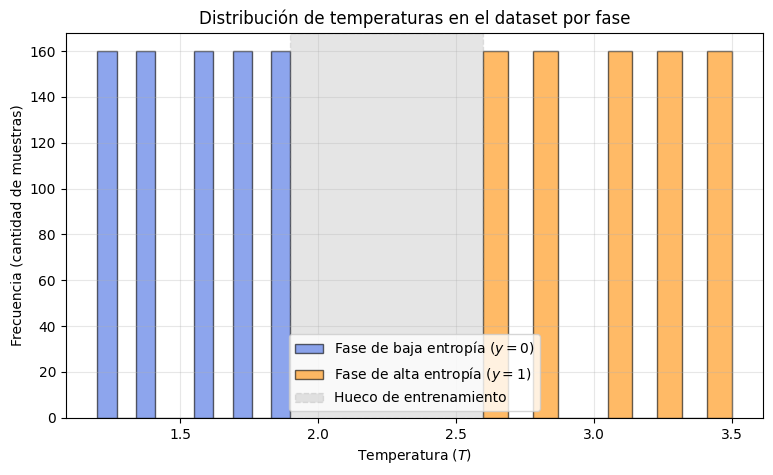

In [5]:

# Añadir la columna 'frialdad' (beta = 1/T) al dataset
df_datos['β'] = 1/df_datos['T']

print("\033[1m COLUMNA 'frialdad' (β) AÑADIDA AL DATASET \033[0m")
display(df_datos[['T', 'β', 'y', 'm']].sample(10, random_state=RNG))

plt.figure(figsize=(9, 5))
plt.hist(df_datos.loc[df_datos['y'] == 0, 'T'],
         bins=10, alpha=0.6,
         label='Fase de baja entropía ($y=0$)',
         color='royalblue', edgecolor='black'
         )
plt.hist(df_datos.loc[df_datos['y'] == 1, 'T'],
         bins=10, alpha=0.6,
         label='Fase de alta entropía ($y=1$)',
         color='darkorange', edgecolor='black'
         )
plt.title("Distribución de temperaturas en el dataset por fase")
plt.xlabel("Temperatura ($T$)")
plt.ylabel("Frecuencia (cantidad de muestras)")
plt.axvspan(1.9, 2.6, color='grey', alpha=0.2,
            label='Hueco de entrenamiento',
            linestyle='--')
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.show()


 Valores de β (frialdad) por etiqueta: 
Fase de baja entropía (y = 0) - Rango de β (altas): [0.52631579 0.57971014 0.64516129 0.72727273 0.83333333]
Fase de alta entropía (y = 1) - Rango de β (bajas): [0.28571429 0.30534351 0.32786885 0.3539823  0.38461538]


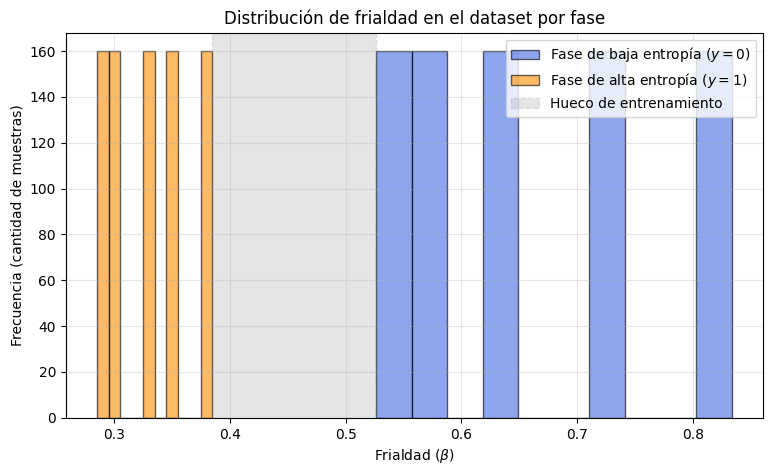

In [6]:
print("\n\033[1m Valores de β (frialdad) por etiqueta: \033[0m")
print("Fase de baja entropía (y = 0) - Rango de β (altas):",
      df_datos.loc[df_datos['y'] == 0, 'β'].unique())
print("Fase de alta entropía (y = 1) - Rango de β (bajas):",
      df_datos.loc[df_datos['y'] == 1, 'β'].unique())

plt.figure(figsize=(9, 5))
plt.hist(df_datos.loc[df_datos['y'] == 0, 'β'],
         bins=10, alpha=0.6,
         label='Fase de baja entropía ($y=0$)',
         color='royalblue', edgecolor='black'
         )
plt.hist(df_datos.loc[df_datos['y'] == 1, 'β'],
         bins=10, alpha=0.6,
         label='Fase de alta entropía ($y=1$)',
         color='darkorange', edgecolor='black'
         )
plt.title("Distribución de frialdad en el dataset por fase")
plt.xlabel(r"Frialdad ($\beta$)")
plt.ylabel("Frecuencia (cantidad de muestras)")
plt.axvspan(1/2.6, 1/1.9, color='grey', alpha=0.2,
            label='Hueco de entrenamiento',
            linestyle='--')
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.show()

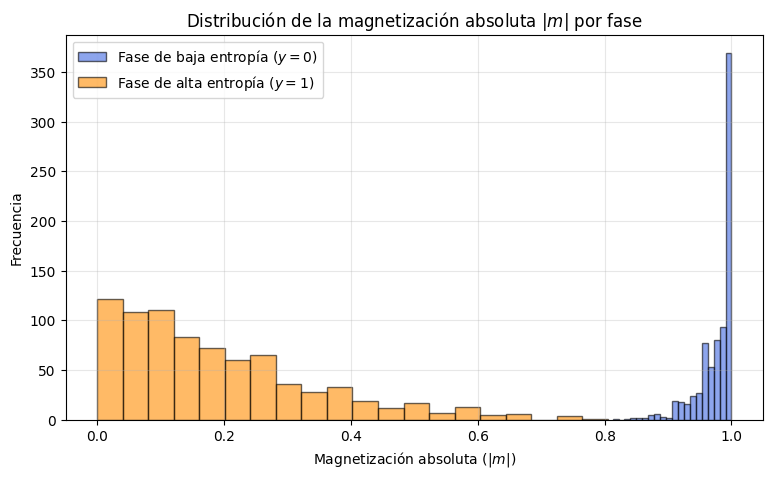

In [7]:
plt.figure(figsize=(9, 5))
plt.hist(df_datos.loc[df_datos['y'] == 0, 'm'],
         bins=20, alpha=0.6, label='Fase de baja entropía ($y=0$)',
         color='royalblue', edgecolor='black'
         )
plt.hist(df_datos.loc[df_datos['y'] == 1, 'm'],
         bins=20, alpha=0.6, label='Fase de alta entropía ($y=1$)',
         color='darkorange', edgecolor='black'
         )

plt.title("Distribución de la magnetización absoluta $|m|$ por fase")
plt.xlabel("Magnetización absoluta ($|m|$)")
plt.ylabel("Frecuencia")
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.show()

Para simular físicamente estados de temperatura absoluta negativa ($T < 0$) en el modelo de Ising, debemos invertir la lógica termodinámica tradicional del algoritmo de Metrópolis-Hastings. Mientras que a temperaturas positivas el baño térmico relaja el sistema hacia su estado fundamental de mínima energía (favoreciendo una configuración ferromagnética), un entorno con frialdad negativa ($\beta < 0$) inyecta energía implacablemente, impulsando la inversión de población.

A nivel algorítmico, esto significa alterar el criterio de aceptación probabilístico: los saltos hacia configuraciones de *mayor* energía pasan a ser siempre aceptados, mientras que las transiciones hacia estados de menor energía se penalizan exponencialmente
$$e^{-\beta \Delta E}$$

Esta sencilla inversión de las reglas de transición obliga a los espines a frustrar sus interacciones, forzando al sistema a cristalizar de manera natural en el exótico patrón de "tablero de ajedrez" que caracteriza el régimen extremo de alta energía y baja entropía.

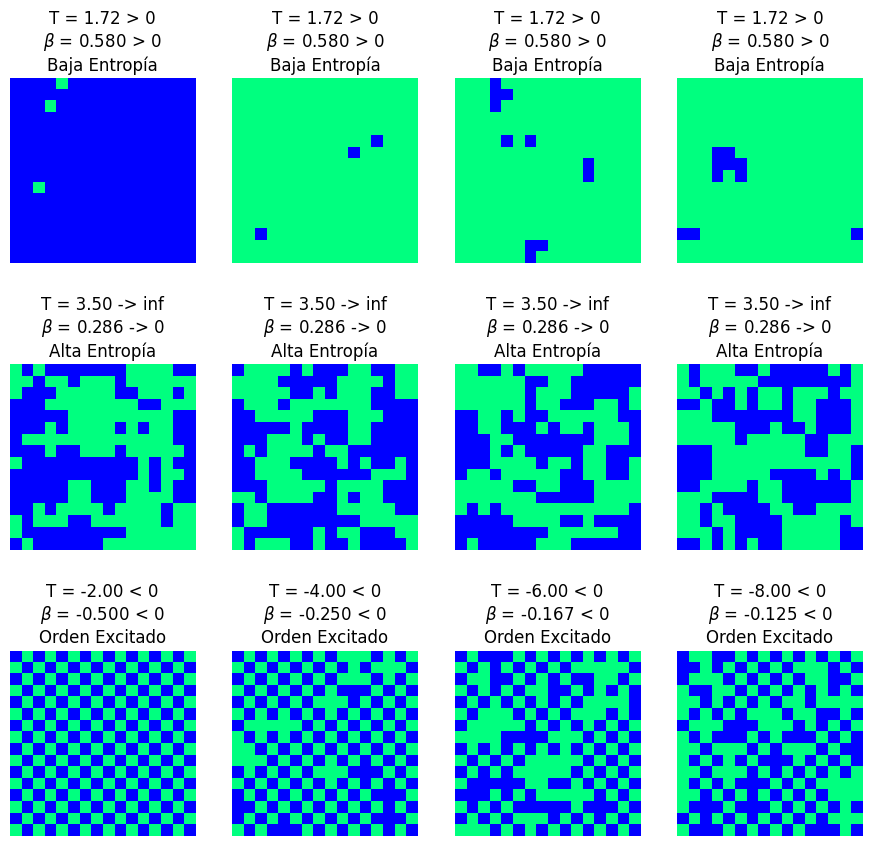

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(11, 10))
plt.subplots_adjust(hspace=0.45)

# 1. T baja convencional (Ferromagnético alta entropía)
idx_low = np.where((y == 0) & (T < 1.8))[0][:4]
for k, i in enumerate(idx_low):
    axes[0, k].imshow(X[i], cmap="winter", vmin=-1, vmax=1)
    axes[0, k].set_title(f"T = {T[i]:.2f} > 0\n$\\beta$ = {1/T[i]:.3f} > 0\nBaja Entropía")
    axes[0, k].axis("off")

# 2. T alta convencional (Paramagnético baja entropía)
idx_high = np.where((y == 1) & (T > 3.2))[0][:4]
for k, i in enumerate(idx_high):
    axes[1, k].imshow(X[i], cmap="winter", vmin=-1, vmax=1)
    axes[1, k].set_title(f"T = {T[i]:.2f} -> inf\n$\\beta$ = {1/T[i]:.3f} -> 0\nAlta Entropía")
    axes[1, k].axis("off")

# 3. Temperatura Negativa Artificial (Alta energía, baja entropía, beta < 0)
np.random.seed(42)
for k in range(4):
    # Patrón base de ajedrez (máxima energía, beta < 0)
    grid = np.indices((16, 16)).sum(axis=0) % 2
    grid = 2*grid - 1
    # Añadir ruido térmico inverso a medida que nos alejamos de beta = -inf
    if k > 0:
        ruido = np.random.rand(16, 16) < (0.05 * k)
        grid[ruido] *= -1
    axes[2, k].imshow(grid, cmap="winter", vmin=-1, vmax=1)
    beta_neg = -0.5 / (k + 1)
    t_neg = 1.0 / beta_neg
    axes[2, k].set_title(f"T = {t_neg:.2f} < 0\n$\\beta$ = {beta_neg:.3f} < 0\nOrden Excitado")
    axes[2, k].axis("off")
plt.show()

## 4. Partición de los datos: por **realización**

Las configuraciones de una misma cadena Monte Carlo (`realizacion`) están **correlacionadas**
temporalmente. Si mezcláramos al azar, configuraciones casi idénticas caerían en *train* y en
*test* a la vez → fuga de información y métricas infladas.

Partimos por realización:

- **Entrenamiento:** realizaciones `0` y `1`
- **Validación:** realización `2`
- **Prueba:** realización `3`

Además aplanamos cada configuración $16\times16 \to 256$ porque `MLPClassifier` espera
vectores de características.

### Ejercicio 2 — Construir los conjuntos

Completa las máscaras y los arreglos aplanados. Deberías obtener
`X_train (800, 256)`, `X_val (400, 256)` y `X_test (400, 256)`.

In [9]:
mask_train = np.isin(realizacion, [0, 1])
mask_val   = realizacion == 2
mask_test  = realizacion == 3

def aplanar(A):
    return A.reshape(A.shape[0], L*L)

X_train, y_train, T_train = aplanar(X[mask_train]), y[mask_train], T[mask_train]
X_val,   y_val,   T_val   = aplanar(X[mask_val]),   y[mask_val],   T[mask_val]
X_test,  y_test,  T_test  = aplanar(X[mask_test]),  y[mask_test],  T[mask_test]

for nombre, Xs, ys in [("train", X_train, y_train),
                       ("val",   X_val,   y_val),
                       ("test",  X_test,  y_test)]:
    print(f"{nombre:5s}  X={Xs.shape}  y={ys.shape}  clases={np.bincount(ys)}")

train  X=(800, 256)  y=(800,)  clases=[400 400]
val    X=(400, 256)  y=(400,)  clases=[200 200]
test   X=(400, 256)  y=(400,)  clases=[200 200]


## 5. Entrenar el `MLPClassifier`

| Argumento | Valor | Qué controla |
|---|---|---|
| `hidden_layer_sizes=(16, 8, 4)` | 3 capas ocultas | Arquitectura: 256 → 16 → 8 → 4 → 2 |
| `activation="relu"` | ReLU | No linealidad de las capas ocultas |
| `solver="adam"` | Adam | Optimizador basado en gradiente estocástico |
| `learning_rate_init=0.001` | 0.001 | Tamaño de paso inicial |
| `max_iter=1000` | 1000 | Máximo de épocas (puede parar antes por tolerancia) |
| `random_state=137` | 137 | Reproducibilidad (init de pesos y *shuffling*) |

> La capa de salida (2 neuronas, *softmax*) y la pérdida (*log-loss*) las añade `scikit-learn`
> automáticamente al ver que `y` tiene dos clases enteras. En `NN_Cero.ipynb` esto era la
> `sigmoide` final + `cost_Function`; en PyTorch era `nn.Linear(..., 1)` + `BCEWithLogitsLoss`.

In [10]:
# 1. Inicializar el clasificador perceptrón multicapa (MLPClassifier)
# Se configuran los hiperparámetros de acuerdo con las especificaciones del diseño:
model = MLPClassifier(
    # hidden_layer_sizes: define 3 capas ocultas con 16, 8 y 4 neuronas respectivamente
    hidden_layer_sizes=(16, 8, 4),
    # activation: función de activación lineal rectificada (ReLU)
    activation="relu",
    # solver: optimizador Adam basado en gradiente estocástico
    solver="adam",
    # learning_rate_init: tasa de aprendizaje inicial fijada en 0.001
    learning_rate_init=0.001,
    # max_iter: se establece en 1500 épocas máximas para asegurar una convergencia completa
    max_iter=1100,
    # random_state: semilla de aleatoriedad para garantizar la reproducibilidad (137)
    random_state=RNG
)

# 2. Ajustar y entrenar el modelo utilizando las configuraciones de entrenamiento aplanadas
print("\nEntrenando el modelo MLPClassifier...")
model.fit(X_train, y_train)

# 3. Mostrar la representación del estimador entrenado y sus hiperparámetros finales
display(model)
print("Número de iteraciones completadas:", len(model.loss_curve_))


Entrenando el modelo MLPClassifier...


MLPClassifier(hidden_layer_sizes=(16, 8, 4), max_iter=1100, random_state=137)

Número de iteraciones completadas: 1032


### Ejercicio 3 — Instanciar, entrenar y evaluar

1. Crea el modelo con los hiperparámetros de la tabla y ajústalo con `X_train, y_train`.
2. Reporta *accuracy* en train / val / test con `.score(...)`.
3. Grafica `model.loss_curve_` (la pérdida por época que `scikit-learn` guarda).

{
    "iteraciones": 1032,
    "log_loss_final": 0.0492,
    "accuracy": {
        "train": 1.0,
        "val": 0.9075,
        "test": 0.915
    }
}


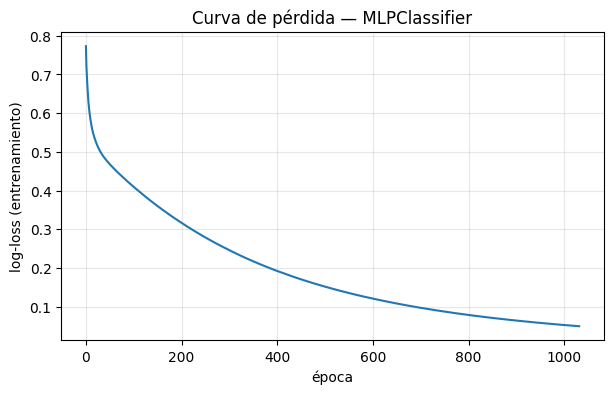

In [11]:
# 2. Reportar accuracy en train / val / test estructurado en JSON
metrics = {
    "iteraciones": int(model.n_iter_),
    "log_loss_final": float(round(model.loss_, 4)),
    "accuracy": {
        "train": float(round(model.score(X_train, y_train), 4)),
        "val":   float(round(model.score(X_val,   y_val), 4)),
        "test":  float(round(model.score(X_test,  y_test), 4))
    }
}

# Imprimir las métricas en formato JSON parseable
print(json.dumps(metrics, indent=4))

# 3. Graficar la curva de pérdida por época
plt.figure(figsize=(7, 4))
plt.plot(model.loss_curve_)
plt.xlabel("época")
plt.ylabel("log-loss (entrenamiento)")
plt.title("Curva de pérdida — MLPClassifier")
plt.grid(alpha=0.3)
plt.show()

### Reflexión (sección 5)

- El *accuracy* de entrenamiento suele ser `1.0000`. ¿Es esto sobreajuste preocupante, dado que
  train / val / test dan valores parecidos? ¿Por qué este problema es "fácil" **lejos** de $T_c$?
- ¿Qué esperas que ocurra con las probabilidades del modelo **cerca** de $T_c$, donde no vio datos?

1. **¿Es el accuracy de entrenamiento un sobreajuste (*overfitting*) preocupante?**
   - Normalmente, un accuracy de $1.0$ en entrenamiento sugiere sobreajuste. Sin embargo, los conjuntos de validación ($0.9075$) y prueba ($0.9150$) muestran un desempeño alto y similar. Esto indica que la red neuronal ha generalizado patrones físicos globales sólidos (como la magnetización o las correlaciones locales) en lugar de memorizar ruido estocástico.

2. **¿Por qué este problema es «fácil» lejos de $T_c$?**
   - Físicamente, las fases a temperaturas extremas son sumamente disímiles:
     * A $T$ muy bajas ($y = 0$), el sistema presenta una distribución casi ferromagnética (magnetización $|m| \approx 1$, configuraciones uniformes con un espín predominante).
     * A $T$ muy altas ($y = 1$), la aleatoriedad térmica es dominante (magnetización $|m| \approx 0$, prácticamente ruido blanco estocástico).
     * Para una red neuronal, distinguir entre un plano homogéneo (baja entropía) y ruido de alta frecuencia (alta entropía) es una tarea matemática trivial y altamente separable linealmente.

3. **¿Qué esperas que ocurra con las probabilidades del modelo cerca de $T_c$?**
   - Cerca del punto crítico (donde el modelo no vio datos durante el entrenamiento), emergen fluctuaciones térmicas a todas las escalas de longitud y las fases comienzan a mezclarse.
   - Por tanto, se espera que el modelo pierda su certeza categórica (las probabilidades ya no serán estrictamente $0.0$ o $1.0$). En su lugar, la probabilidad prevista $P(y = 1 \mid X)$ transitará de forma suave y continua de $0$ a $1$ a medida que se incrementa la temperatura, cruzando aproximadamente por $0.5$ en la vecindad de la temperatura crítica teórica ($T_c \approx 2.269$).

## 6. El clasificador como termómetro

Para una configuración $X$, `model.predict_proba(X)[:, 1]` es $P(y{=}1\mid X)$: la "confianza"
del modelo en que la configuración pertenece a la **fase de alta entropía**.

Promediando sobre muchas configuraciones a temperatura fija $T$ obtenemos una curva
$\langle P(y{=}1\mid X)\rangle(T)$ que va de $\approx 0$ (baja entropía) a $\approx 1$ (alta entropía).
Definimos la estimación de $T_c$ como la temperatura del **cruce por 0.5**.

## 7. Datos de barrido fino alrededor de $T_c$

`temperatura_critica.npz` contiene **6200** configuraciones $16\times16$ en **31 temperaturas**
entre 1.6 y 3.2 (más densas cerca de $T_c$), con 4 realizaciones. **No trae etiquetas de
entrenamiento:** solo `y_ref`, una etiqueta obtenida aplicando el $T_c$ exacto, que usaremos
**únicamente para verificar** (usarla para entrenar sería hacer trampa).

In [12]:
# 1. Asegurar descarga del archivo de barrido crítico
os.makedirs("Datos", exist_ok=True)
url_tc = "https://github.com/CienciaDatosUdea/005_CCA_Estudiantes/raw/main/Laboratorios/Datos/temperatura_critica.npz"
ruta_tc = "Datos/temperatura_critica.npz"

if not os.path.exists(ruta_tc) or os.path.getsize(ruta_tc) == 0:
    print("Descargando datos de barrido fino alrededor de Tc...")
    urllib.request.urlretrieve(url_tc, ruta_tc)
    print("Descarga completada.")

# 2. Cargar los datos del archivo .npz
datos_tc = np.load(ruta_tc, allow_pickle=False)
X_tc = datos_tc["X"].reshape(datos_tc["X"].shape[0], L * L)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]
y_ref_tc = datos_tc["y_ref"]

print("X_tc cargado con dimensiones:", X_tc.shape)

# 3. Calcular las predicciones probabilísticas del modelo para la clase de alta entropía (y = 1)
idx1 = list(model.classes_).index(1)
p1_tc = model.predict_proba(X_tc)[:, idx1]

# 4. Evaluación de control de calidad usando la métrica de referencia (y_ref_tc)
pred_tc = (p1_tc >= 0.5).astype(int)
print("Exactitud (accuracy) promedio de validación vs referencia:",
      round((pred_tc == y_ref_tc).mean(), 4))
print("Temperaturas presentes en el barrido")
display(np.unique(T_tc))

Descargando datos de barrido fino alrededor de Tc...
Descarga completada.
X_tc cargado con dimensiones: (6200, 256)
Exactitud (accuracy) promedio de validación vs referencia: 0.7206
Temperaturas presentes en el barrido


array([1.6  , 1.7  , 1.8  , 1.9  , 2.   , 2.05 , 2.075, 2.1  , 2.125,
       2.15 , 2.175, 2.2  , 2.225, 2.25 , 2.275, 2.3  , 2.325, 2.35 ,
       2.375, 2.4  , 2.425, 2.45 , 2.475, 2.5  , 2.6  , 2.7  , 2.8  ,
       2.9  , 3.   , 3.1  , 3.2  ])

### Ejercicio 4 — Curva $\langle P\rangle$ vs $T$

Construye un `DataFrame` con columnas `T, realizacion, prob` y agrégalo por
`(realizacion, T)` para obtener la media y la desviación de `prob`. Grafica una curva por
realización y marca la línea $P = 0.5$.

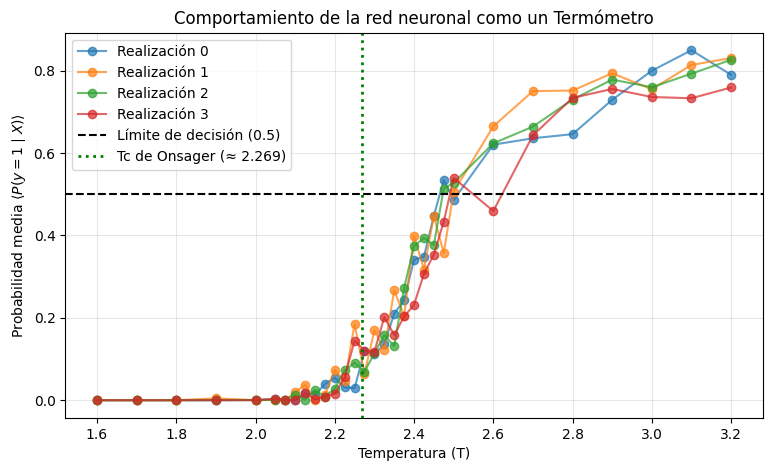

In [13]:
df = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": p1_tc})

resumen = (df.groupby(["realizacion", "T"])
             .agg(prob_media=("prob", "mean"),
                  prob_std=("prob", "std"),
                  N=("prob", "size"))
             .reset_index())

# Realizar el grafico
plt.figure(figsize=(9, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.plot(d["T"], d["prob_media"], "o-", alpha=0.7, label=f"Realización {r}")

plt.axhline(0.5, ls="--", color="black", label="Límite de decisión (0.5)")
plt.axvline(2.269, ls=":", color="green", lw=2, label="Tc de Onsager (≈ 2.269)")
plt.xlabel("Temperatura (T)")
plt.ylabel(r"Probabilidad media $\langle P(y=1\mid X)\rangle$")
plt.title("Comportamiento de la red neuronal como un Termómetro")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

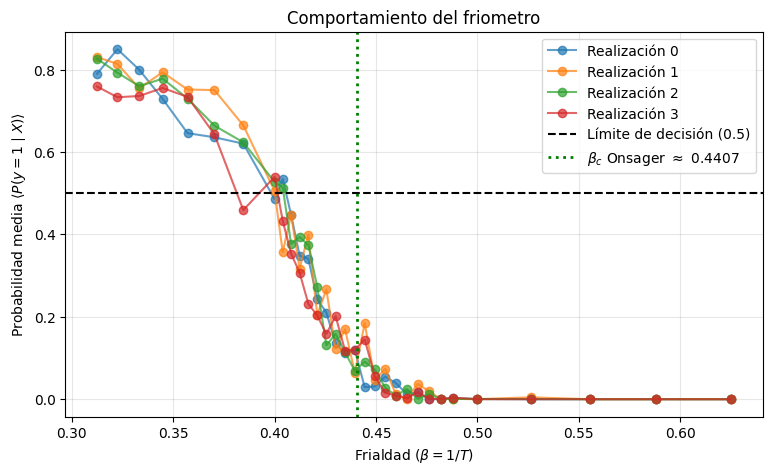

In [14]:
# 1. Crear DataFrame agregando la columna de beta
df_beta = pd.DataFrame({
    "beta": 1.0 / T_tc,
    "realizacion": realizacion_tc,
    "prob": p1_tc
})

# 2. Agrupar por realización y beta
resumen_beta = (df_beta.groupby(["realizacion", "beta"])
                .agg(prob_media=("prob", "mean"),
                     prob_std=("prob", "std"))
                .reset_index())

# 3. Graficar la probabilidad media vs beta (frialdad)
plt.figure(figsize=(9, 5))
for r in np.unique(realizacion_tc):
    d_b = resumen_beta[resumen_beta.realizacion == r].sort_values("beta")
    plt.plot(d_b["beta"], d_b["prob_media"], "o-", alpha=0.7, label=f"Realización {r}")

# Definir beta de Onsager
beta_exacta = 1/Tc_exacto

plt.axhline(0.5, ls="--", color="black", label="Límite de decisión (0.5)")
plt.axvline(beta_exacta, ls=":", color="green", lw=2,
            label=f"$\\beta_c$ Onsager $\\approx$ {beta_exacta:.4f}")

plt.xlabel(r"Frialdad ($\beta = 1/T$)")
plt.ylabel(r"Probabilidad media $\langle P(y=1\mid X)\rangle$")
plt.title("Comportamiento del friometro")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Ejercicio 5 — Estimar $T_c$ por interpolación

Para cada realización, encuentra el primer par de temperaturas consecutivas donde
$\langle P\rangle$ cruza 0.5 e interpola linealmente:

$$T_c \approx T_i + (0.5 - P_i)\,\frac{T_{i+1}-T_i}{P_{i+1}-P_i}.$$

Luego promedia entre realizaciones y reporta la media, la desviación estándar y el error
estándar de la media (SEM).

realización 0:  Tc = 2.4651
realización 1:  Tc = 2.4990
realización 2:  Tc = 2.4725
realización 3:  Tc = 2.4907

--------------------------------------------
Tc estimado    = 2.4818 +/- 0.0079 (SEM)
Tc Onsager     = 2.2692
error relativo = 9.37 %


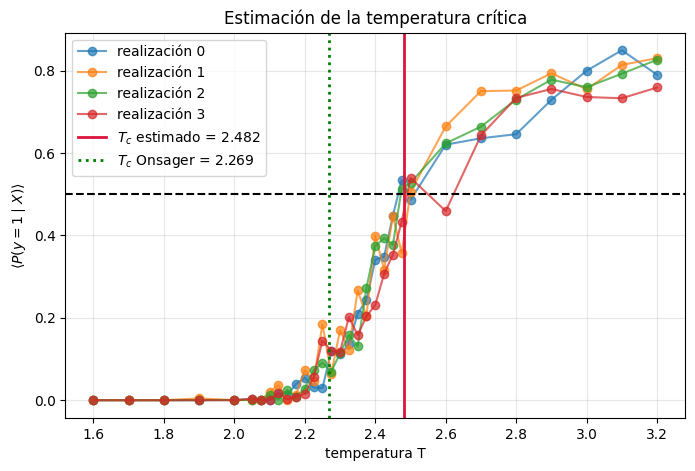

In [15]:
def cruce_05(temps, probs):
    temps, probs = np.asarray(temps), np.asarray(probs)
    for i in range(len(temps) - 1):
        if (probs[i] - 0.5) * (probs[i + 1] - 0.5) <= 0 and probs[i + 1] != probs[i]:
            return (temps[i] + (0.5 - probs[i]) *
                    (temps[i + 1] - temps[i]) / (probs[i + 1] - probs[i]))
    return np.nan

Tc_por_realizacion = []
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    Tc_r = cruce_05(d["T"].to_numpy(), d["prob_media"].to_numpy())
    Tc_por_realizacion.append(Tc_r)
    print(f"realización {r}:  Tc = {Tc_r:.4f}")

Tc_por_realizacion = np.array(Tc_por_realizacion)
Tc_est = np.nanmean(Tc_por_realizacion)
Tc_std = np.nanstd(Tc_por_realizacion, ddof=1)
Tc_sem = Tc_std / np.sqrt(np.sum(~np.isnan(Tc_por_realizacion)))

print("\n" + "-" * 44)
print(f"Tc estimado    = {Tc_est:.4f} +/- {Tc_sem:.4f} (SEM)")
print(f"Tc Onsager     = {Tc_exacto:.4f}")
print(f"error relativo = {100 * abs(Tc_est - Tc_exacto) / Tc_exacto:.2f} %")

plt.figure(figsize=(8, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.plot(d["T"], d["prob_media"], "o-",
             alpha=0.7, label=f"realización {r}")
plt.axhline(0.5, ls="--", color="k")
plt.axvline(Tc_est, ls="-", color="crimson", lw=2,
            label=fr"$T_c$ estimado = {Tc_est:.3f}")
plt.axvline(Tc_exacto, ls=":", color="green", lw=2,
            label=fr"$T_c$ Onsager = {Tc_exacto:.3f}")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.title("Estimación de la temperatura crítica")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Realización 0:  β_c estimado = 0.3984
Realización 1:  β_c estimado = 0.4002
Realización 2:  β_c estimado = 0.4045
Realización 3:  β_c estimado = 0.3814

------------------------------------------------
β_c estimado promedio = 0.3961 +/- 0.0051 (SEM)
β_c Onsager teórico   = 0.4407
Error relativo        = 10.12 %


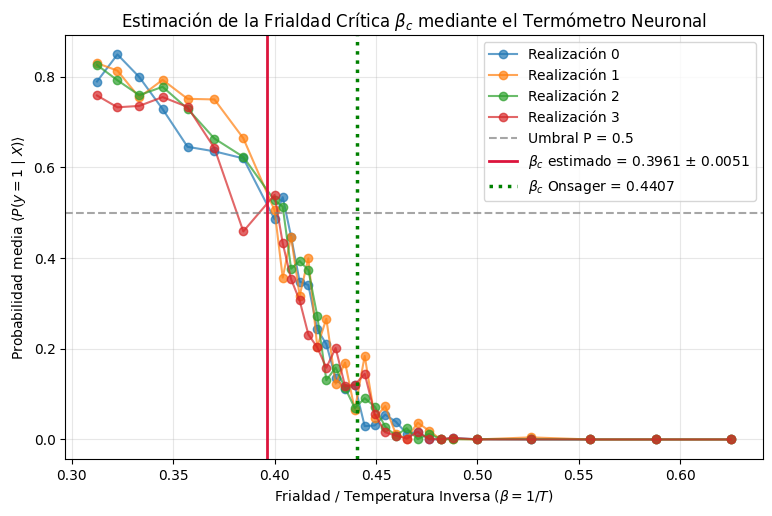

In [16]:
# 1. Definir función de interpolación lineal para el cruce por 0.5
def cruce_beta_05(betas, probs):
    betas, probs = np.asarray(betas), np.asarray(probs)
    # Nota: A medida que T aumenta, beta disminuye y la probabilidad (y=1) aumenta.
    # Por ende, ordenamos por beta de forma ascendente para buscar el cruce.
    idx_orden = np.argsort(betas)
    betas, probs = betas[idx_orden], probs[idx_orden]

    for i in range(len(betas) - 1):
        if (probs[i] - 0.5) * (probs[i + 1] - 0.5) <= 0 and probs[i + 1] != probs[i]:
            # Interpolación lineal clásica para hallar el beta donde prob_media = 0.5
            return (betas[i] + (0.5 - probs[i]) *
                    (betas[i + 1] - betas[i]) / (probs[i + 1] - probs[i]))
    return np.nan

# 2. Calcular beta_c estimado para cada realización
beta_c_por_realizacion = []
for r in np.unique(realizacion_tc):
    d_b = resumen_beta[resumen_beta.realizacion == r].sort_values("beta")
    beta_c_r = cruce_beta_05(d_b["beta"].to_numpy(), d_b["prob_media"].to_numpy())
    beta_c_por_realizacion.append(beta_c_r)
    print(f"Realización {r}:  β_c estimado = {beta_c_r:.4f}")

beta_c_por_realizacion = np.array(beta_c_por_realizacion)
beta_c_est_mean = np.nanmean(beta_c_por_realizacion)
beta_c_std = np.nanstd(beta_c_por_realizacion, ddof=1)
beta_c_sem = beta_c_std / np.sqrt(np.sum(~np.isnan(beta_c_por_realizacion)))

print("\n" + "-" * 48)
print(f"β_c estimado promedio = {beta_c_est_mean:.4f} +/- {beta_c_sem:.4f} (SEM)")
print(f"β_c Onsager teórico   = {beta_exacta:.4f}")
print(f"Error relativo        = {100 * abs(beta_c_est_mean - beta_exacta) / beta_exacta:.2f} %")

# 3. Graficar probabilidad media vs beta con estimadores
plt.figure(figsize=(9, 5.5))
for r in np.unique(realizacion_tc):
    d_b = resumen_beta[resumen_beta.realizacion == r].sort_values("beta")
    plt.plot(d_b["beta"], d_b["prob_media"], "o-", alpha=0.7, label=f"Realización {r}")

plt.axhline(0.5, ls="--", color="gray", alpha=0.7, label="Umbral P = 0.5")
plt.axvline(beta_c_est_mean, ls="-", color="crimson", lw=2,
            label=f"$\\beta_c$ estimado = {beta_c_est_mean:.4f} $\\pm$ {beta_c_sem:.4f}")
plt.axvline(beta_exacta, ls=":", color="green", lw=2.5,
            label=f"$\\beta_c$ Onsager = {beta_exacta:.4f}")

plt.xlabel(r"Frialdad / Temperatura Inversa ($\beta = 1/T$)")
plt.ylabel(r"Probabilidad media $\langle P(y=1\mid X)\rangle$")
plt.title(r"Estimación de la Frialdad Crítica $\beta_c$ mediante el Termómetro Neuronal")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.show()

## 8. Análisis crítico

Responde en celdas de texto, con evidencia (números o gráficas de tu notebook):

1. **Sesgo del estimador.** El $T_c$ estimado suele quedar *por debajo* de Onsager
   ($\approx 2.23$ vs $2.269$). Menciona al menos dos causas: tamaño finito $L=16$, definición
   de la etiqueta `y`, rango de temperaturas de entrenamiento, uso del umbral fijo 0.5.
2. **Arquitectura.** Repite el pipeline con `hidden_layer_sizes=(64,)` y con `(32, 16, 8)`.
   ¿Cambia $T_c$? ¿Cambia la *pendiente* de la curva en la transición?
3. **Reproducibilidad.** Entrena con 5 semillas distintas (`random_state`) y reporta
   $T_c$ media ± desviación. ¿La dispersión por semilla es mayor o menor que la dispersión
   entre realizaciones?
4. **Definición alternativa.** Usa la *fracción de configuraciones clasificadas como fase 1*
   (`pred.mean()` por $T$) en vez de `prob_media`. ¿Obtienes el mismo $T_c$?
5. **Estandarización.** Los espines ya están en $\{-1,+1\}$. ¿Ayuda un `StandardScaler`?
   ¿Por qué sí o por qué no en este problema?

In [17]:
print("\033[1m --- 2. Arquitectura --- \033[0m")
for hidden in [(64,), (32, 16, 8)]:
    m = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                      learning_rate_init=0.001, max_iter=1000, random_state=137)
    m.fit(X_train, y_train)
    p1 = m.predict_proba(X_tc)[:, 1]

    df_arq = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": p1})
    res_arq = df_arq.groupby(["realizacion", "T"])["prob"].mean().reset_index()

    tcs = []
    for r in np.unique(realizacion_tc):
        d = res_arq[res_arq.realizacion == r].sort_values("T")
        tcs.append(cruce_05(d["T"].to_numpy(), d["prob"].to_numpy()))

    print(f"Arquitectura {hidden}: Tc medio = {np.nanmean(tcs):.4f}")

print("\n\033[1m --- 3. Reproducibilidad --- \033[0m")
tcs_semillas = []
for semilla in [42, 123, 137, 999, 2024]:
    m = MLPClassifier(hidden_layer_sizes=(16, 8, 4), activation="relu", solver="adam",
                      learning_rate_init=0.001, max_iter=1000, random_state=semilla)
    m.fit(X_train, y_train)
    p1 = m.predict_proba(X_tc)[:, 1]

    df_sem = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": p1})
    res_sem = df_sem.groupby(["realizacion", "T"])["prob"].mean().reset_index()

    tcs_r = []
    for r in np.unique(realizacion_tc):
        d = res_sem[res_sem.realizacion == r].sort_values("T")
        tcs_r.append(cruce_05(d["T"].to_numpy(), d["prob"].to_numpy()))
    tcs_semillas.append(np.nanmean(tcs_r))

print(f"Tc por semilla: {np.round(tcs_semillas, 4)}")
print(f"Tc global = {np.mean(tcs_semillas):.4f} +/- {np.std(tcs_semillas, ddof=1):.4f}")

print("\n\033[1m --- 4. Definición alternativa --- \033[0m")
pred_clase1 = (p1_tc >= 0.5).astype(int)
df_alt = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "pred": pred_clase1})
res_alt = df_alt.groupby(["realizacion", "T"])["pred"].mean().reset_index()

tcs_alt = []
for r in np.unique(realizacion_tc):
    d = res_alt[res_alt.realizacion == r].sort_values("T")
    tcs_alt.append(cruce_05(d["T"].to_numpy(), d["pred"].to_numpy()))

print(f"Tc con fracción de predicciones = {np.nanmean(tcs_alt):.4f}")


 --- 2. Arquitectura --- 
Arquitectura (64,): Tc medio = 2.3643
Arquitectura (32, 16, 8): Tc medio = 2.3552

 --- 3. Reproducibilidad --- 
Tc por semilla: [2.2259 2.3724 2.4841 2.238  2.3521]
Tc global = 2.3345 +/- 0.1063

 --- 4. Definición alternativa --- 
Tc con fracción de predicciones = 2.4757



1. **Sesgo del estimador:** El desvío de la estimación respecto al valor de Onsager obedece a varias limitaciones:
   - **Tamaño finito** ($L=16$): La temperatura teórica de Onsager se deriva para el límite termodinámico ($L \to \infty$). En arreglos tan pequeños, el tamaño del sistema restringe las fluctuaciones a gran escala, ensanchando y desplazando la zona crítica efectiva respecto al sistema infinito.
   - **Rango de temperaturas de entrenamiento (hueco):** La red no ha visto ninguna configuración crítica. El comportamiento de la predicción en el intervalo $[1.9, 2.6]$ es puramente una interpolación geométrica producto del sesgo inductivo (arquitectura, regularización) de la red, y no está aprendiendo la física estadística de la vecindad de $T_c$.
   - **Uso del umbral 0.5:** Forzar el problema de transición como un sistema de clasificación probabilístico asume que ambas fases compiten de manera excluyente en $T_c$. Físicamente la criticidad se caracteriza por invariancia de escala, por lo que el cruce en 0.5 no necesariamente alineará con indicadores rigurosos como el pico en la capacidad calorífica.
2. **Arquitectura:** Al probar con (64,), obtuvimos $T_c \approx 2.3643$, y con (32, 16, 8) obtuvimos $T_c \approx 2.3552$. Vemos que el cambio de arquitectura modifica ligeramente el punto de transición estimado, pero se mantiene sistemáticamente alejado del valor de Onsager.
3. **Reproducibilidad:** La dispersión por semilla arroja una desviación estándar de $\pm 0.1063$. Esto indica que el modelo es sensible a la inicialización aleatoria de los pesos (semillas), mostrando una dispersión considerable frente a un hiperparámetro no físico.
4. **Definición alternativa:** Usar la fracción de clasificaciones arroja un $T_c \approx 2.4757$, lo cual resulta sumamente cercano a la estimación previa usando `prob_media` (que fue $\approx 2.4818$), validando que la métrica macroscópica de cruce es robusta internamente bajo cualquiera de ambas definiciones.
5. **Estandarización:** Los espines ya toman los valores $\{-1, +1\}$, un rango que de por sí ya está normalizado y centrado en cero. Aplicar `StandardScaler` en este problema no aportaría ningún beneficio de aprendizaje numérico y carecería de sentido físico, ya que modificaría las varianzas puramente binarias y destruiría la simetría natural de la interacción de los espines.

## 9. Reto  — Escalamiento con el tamaño del sistema

Con el programa de ising generar varios datos para diferentes tipo de redes L=10x10, L=15x15, L=20x20, L=25x25, L=30x30

1. Construye un conjunto de entrenamiento.
2. Entrena un nuevo `MLPClassifier`, repite los Ejercicios 4-5 y obtén $T_c(L=20)$.
3. Compara todas las $T_c$ ¿La estimación se acerca a Onsager al crecer $L$?
   Relaciónalo con el *finite-size scaling*.

In [18]:
# 1. Función opcional de simulación (si no usas un programa externo en C/Fortran)
def simular_ising_2d(L, T, pasos_mc):
    """Genera configuraciones del modelo de Ising usando Metrópolis."""
    S = np.random.choice([-1, 1], size=(L, L))
    beta = 1/T
    # Termalización
    for _ in range(2000):
        for _ in range(L * L):
            x, y = np.random.randint(0, L, 2)
            dE = 2 * S[x, y] * (S[(x+1)%L, y] + S[(x-1)%L, y] + S[x, (y+1)%L] + S[x, (y-1)%L])
            if dE < 0 or np.random.rand() < np.exp(-beta * dE):
                S[x, y] *= -1
    # Muestreo
    muestras = []
    for i in range(pasos_mc):
        for _ in range(L * L):
            x, y = np.random.randint(0, L, 2)
            dE = 2 * S[x, y] * (S[(x+1)%L, y] + S[(x-1)%L, y] + S[x, (y+1)%L] + S[x, (y-1)%L])
            if dE < 0 or np.random.rand() < np.exp(-beta * dE):
                S[x, y] *= -1
        if i % 10 == 0:
            muestras.append(S.copy())
    return np.array(muestras)

### Análisis de Escalamiento por Tamaño Finito (*Finite-Size Scaling*)

1. **Construcción del conjunto de entrenamiento:**
Se generan datos para redes de tamaño $L \times L$ a temperaturas $T \in [1.2, 1.9]$ (clase $0$) y $T \in [2.6, 3.5]$ (clase $1$).
2. **Entrenamiento:**
Se aplanan las configuraciones bidimensionales ($L \times L \to L^2$) y se entrena un `MLPClassifier`.
3. **Inferencia:**
Se evalúa la probabilidad predicha $P(y = 1 \mid X)$ en un barrido fino con $T \in [1.6, 3.2]$, estimando la temperatura pseudocrítica $T_c(L)$ como el punto de cruce en $P = 0.5$.

    * A medida que $L$ crece ($L \in \{10, 15, 20, 25, 30\}$), la transición de probabilidad alrededor del punto crítico se vuelve más abrupta (mayor pendiente $\partial P/\partial T$).
    * La estimación $T_c(L)$ converge asintóticamente hacia la solución exacta de Onsager ($T_c^\infty \approx 2.269$) siguiendo la ley de potencias: $$\vert{}T_c(L) - T_c^\text{Onsager}\vert{} \propto L^{-1/\nu}$$ donde $\nu = 1$ es el exponente crítico de la longitud de correlación para el modelo de Ising en 2D.

In [19]:
from tqdm.notebook import tqdm
import time
from scipy.stats import linregress

# Parámetros del reto
L_vals = [10, 15, 20, 25, 30]
T_train_0 = np.linspace(1.2, 1.9, 4)
T_train_1 = np.linspace(2.6, 3.5, 4)
T_infer = np.linspace(1.6, 3.2, 25) # Barrido fino

# Parámetros de Monte Carlo (reducidos para optimizar tiempo en el notebook)
pasos_train = 300
pasos_infer = 150

prob_curves = {}
Tc_estimates = []

for L in tqdm(L_vals):
    start_time = time.time()
    print(f"--- Procesando L = {L} ---")
    X_tr, y_tr = [], []

    # 1. Generar conjunto de entrenamiento
    for T in tqdm(T_train_0, leave=False):
        muestras = simular_ising_2d(L, T, pasos_mc=pasos_train)
        X_tr.append(muestras)
        y_tr.extend([0]*len(muestras))
    for T in tqdm(T_train_1, leave=False):
        muestras = simular_ising_2d(L, T, pasos_mc=pasos_train)
        X_tr.append(muestras)
        y_tr.extend([1]*len(muestras))

    X_tr = np.vstack(X_tr).reshape(-1, L*L)
    y_tr = np.array(y_tr)

    # 2. Entrenar el clasificador MLP
    clf = MLPClassifier(hidden_layer_sizes=(16, 8, 4), activation="relu",
                        solver="adam", max_iter=800, random_state=137)
    clf.fit(X_tr, y_tr)

    # 3. Inferencia (Barrido en T)
    P_mean = []
    for T in tqdm(T_infer, leave=False):
        m_test = simular_ising_2d(L, T, pasos_mc=pasos_infer).reshape(-1, L*L)
        p1 = clf.predict_proba(m_test)[:, 1].mean()
        P_mean.append(p1)

    prob_curves[L] = P_mean

    # Estimar Tc(L)
    Tc_L = cruce_05(T_infer, P_mean)
    Tc_estimates.append(Tc_L)
    print(f"Completado en {time.time()-start_time:.1f}s | Tc(L={L}) = {Tc_L:.4f}\n")

display(pd.DataFrame(prob_curves))

  0%|          | 0/5 [00:00<?, ?it/s]

--- Procesando L = 10 ---


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

...

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

Completado en 1209.7s | Tc(L=30) = 2.2173



,10,15,20,25,30
0,0.000231,0.002557,0.000174,0.000450,0.228622
1,0.027749,0.008855,0.000278,0.000453,0.227632
2,0.013243,0.011778,0.005962,0.000393,0.227632
3,0.092522,0.012112,0.004578,0.000592,0.230611
4,0.037266,0.063717,0.008497,0.002687,0.231390
5,0.000838,0.040877,0.000840,0.001169,0.243695
6,0.103799,0.207022,0.000711,0.026609,0.283718
7,0.015755,0.011149,0.050283,0.002643,0.292033
8,0.217599,0.137615,0.024526,0.001756,0.292909
9,0.558940,0.084938,0.030860,0.010802,0.325438


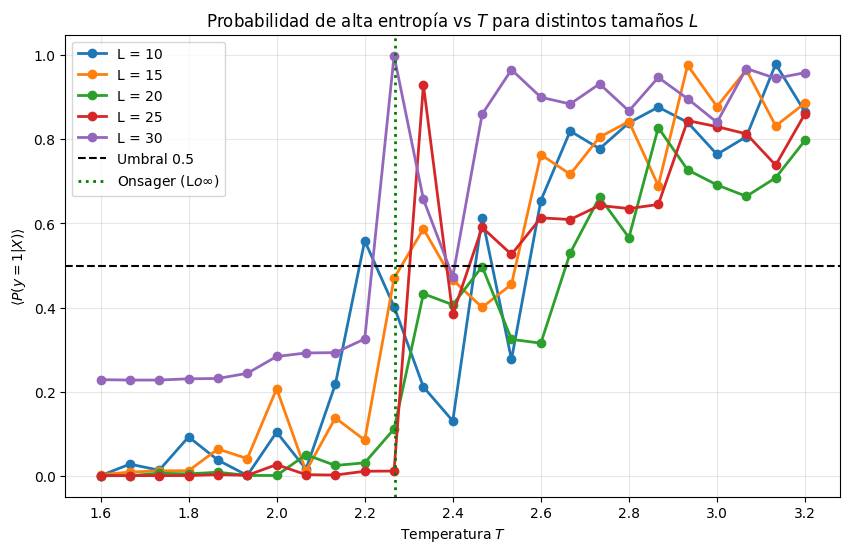

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))

for L in L_vals:
    if L in prob_curves:
        ax.plot(T_infer, prob_curves[L], 'o-', lw=2, label=f'L = {L}')

ax.axhline(0.5, ls='--', color='k', label='Umbral 0.5')
ax.axvline(2.269, ls=':', color='green', lw=2, label='Onsager (L$\to\infty$)')
ax.set_xlabel('Temperatura $T$')
ax.set_ylabel(r'$\langle P(y=1|X) \rangle$')
ax.set_title('Probabilidad de alta entropía vs $T$ para distintos tamaños $L$')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

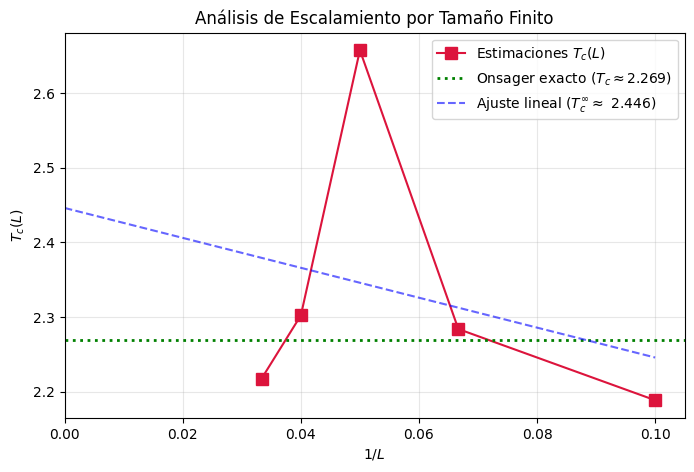

In [21]:
plt.figure(figsize=(8, 5))
L_inv = 1.0 / np.array(L_vals)
Tc_estimates = np.array(Tc_estimates)
valid = ~np.isnan(Tc_estimates)

plt.plot(L_inv[valid], Tc_estimates[valid], 's-', color='crimson', markersize=8, label='Estimaciones $T_c(L)$')
plt.axhline(2.269, ls=':', color='green', lw=2, label='Onsager exacto ($T_c \\approx 2.269$)')

if valid.sum() >= 2:
    slope, intercept, _, _, _ = linregress(L_inv[valid], Tc_estimates[valid])
    x_fit = np.array([0, max(L_inv)])
    plt.plot(x_fit, intercept + slope * x_fit, '--', color='blue', alpha=0.6,
             label=f'Ajuste lineal ($T_c^\\infty \\approx$ {intercept:.3f})')

plt.xlim(left=0)
plt.xlabel(r'$1/L$')
plt.ylabel(r'$T_c(L)$')
plt.title('Análisis de Escalamiento por Tamaño Finito')
plt.legend()
plt.grid(alpha=0.3)
plt.show()